# **04.1 - Convolutional Neural Network: Modified LeNet-5**

This network is a modified LeNet-5 utilizing ReLU and Max Pooling. Its purpose is to learn and predict handwritten numerical digits using the MNIST dataset.

## **Libraries**

In [1]:
import random
import torch
from torch import nn
from torchvision.datasets import mnist
from torch.optim import SGD
from torch.utils.data import DataLoader
from torch.utils.data import random_split
from torchvision.transforms import ToTensor
from matplotlib import pyplot as plt
import copy

## **Hyperparameters**

In [5]:
batch_size = 64
learning_rate = 0.01
nums_epoch = 200 # Epoch is one complete pass through the training set
prev_acc = 0

## **Data Loading, Split, Tensor Conversion**

In [6]:
# Training / Validation / Test Split
train_full = mnist.MNIST(root='./train', train=True, transform=ToTensor())
train_size = int(0.8*len(train_full))
val_size = len(train_full) - train_size

generator = torch.Generator().manual_seed(42) #Reproducible Split for hyperparameter testing

train_dataset, val_dataset = random_split(train_full, [train_size,val_size], generator=generator)
test_dataset = mnist.MNIST(root='./test', train=False, transform=ToTensor())

# Data Loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## **Model**

### **Model Architecture**

In [7]:
# Convolutional Neural Network Architecture
class LeNet5Mod(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 6, 5, stride=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(6, 16, 5, stride=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(256, 120)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(120, 84)
        self.relu4 = nn.ReLU()
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        y = self.conv1(x)
        y = self.relu1(y)
        y = self.pool1(y)
        y = self.conv2(y)
        y = self.relu2(y)
        y = self.pool2(y)
        y = y.view(y.shape[0], -1)
        y = self.fc1(y)
        y = self.relu3(y)
        y = self.fc2(y)
        y = self.relu4(y)
        y = self.fc3(y)
        return y

# Instance, Loss Function, Optimizer
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)
model = LeNet5Mod().to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = SGD(model.parameters(), lr=learning_rate)

cuda


### **Model Training and Validation**

In [ ]:
loss_list = []
val_loss_list = []
training_accuracy_list = []
val_accuracy_list = []

best_val_loss = float('inf')
best_weights = None
best_epoch = None

for epoch in range(nums_epoch):

    # --------------------
    # Training Run
    # --------------------

    for x_batch, y_batch in train_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        prediction = model(x_batch)
        loss = loss_function(prediction, y_batch)

        # Gradient Descent
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # --------------------
    # Training / Validation Evaluation
    # --------------------

    with torch.no_grad():

        # Training loss and accuracy for completed epoch
        train_loss = 0
        training_correct = 0
        training_total = 0

        for x_batch, y_batch in train_loader:

            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            train_prediction = model(x_batch)
            batch_loss = loss_function(train_prediction, y_batch)

            train_loss += batch_loss.item()

            train_class = torch.argmax(train_prediction, dim=1)
            training_correct += (train_class == y_batch).sum().item()
            training_total += len(y_batch)

        train_loss = train_loss / len(train_loader)
        training_accuracy = training_correct / training_total

        loss_list.append(train_loss)
        training_accuracy_list.append(training_accuracy)


        # Validation loss and accuracy for completed epoch
        val_loss = 0
        val_correct = 0
        val_total = 0

        for x_batch, y_batch in val_loader:

            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            val_prediction = model(x_batch)
            batch_loss = loss_function(val_prediction, y_batch)

            val_loss += batch_loss.item()

            val_class = torch.argmax(val_prediction, dim=1)
            val_correct += (val_class == y_batch).sum().item()
            val_total += len(y_batch)

        val_loss = val_loss / len(val_loader)
        val_accuracy = val_correct / val_total

        val_loss_list.append(val_loss)
        val_accuracy_list.append(val_accuracy)


        # Best Weights Tracking
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch


        # Print Epoch Performance
        if epoch % 10 == 0:
            print(
                'epoch = ', epoch,
                ' training loss = ', train_loss,
                ' validation loss = ', val_loss,
                ' difference = ',
                abs(train_loss - val_loss)
            )


# Training Loss vs Validation Loss Plot
plt.plot(loss_list, label='Training Loss')
plt.plot(val_loss_list, label='Validation Loss')

plt.title('Training Loss vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


# -------------------------------------------
# Final Training / Validation Evaluation
# Using best validation weights
# -------------------------------------------

assert best_weights is not None
model.load_state_dict(best_weights)

with torch.no_grad():

    # Training evaluation using best weights
    train_correct = 0
    train_total = 0

    for x_batch, y_batch in train_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        train_prediction = model(x_batch)

        train_class = torch.argmax(train_prediction, dim=1)
        train_correct += (train_class == y_batch).sum().item()
        train_total += len(y_batch)

    training_accuracy = train_correct / train_total


    # Validation evaluation using best weights
    val_correct = 0
    val_total = 0

    for x_batch, y_batch in val_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        val_prediction = model(x_batch)

        val_class = torch.argmax(val_prediction, dim=1)
        val_correct += (val_class == y_batch).sum().item()
        val_total += len(y_batch)

    val_accuracy = val_correct / val_total


# Report Out

print(f"Training Accuracy: {round(training_accuracy, 3)}")
print(f"Validation Accuracy: {round(val_accuracy, 3)}")

print(
    f"Best epoch: {best_epoch}, "
    f"Best validation loss: {best_val_loss}"
)

### **Model Testing and Results**

In [8]:
# Best baseline weights. Remove if new training best-weights are to be used
best_weights = torch.load(
    "lenet5_baseline_best_weights.pth",
    map_location=device
)

assert best_weights is not None
model.load_state_dict(best_weights)

model.eval()

with torch.no_grad():

    test_loss = 0
    test_correct = 0
    test_total = 0

    for x_batch, y_batch in test_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        test_prediction = model(x_batch)
        batch_loss = loss_function(test_prediction, y_batch)

        test_loss += batch_loss.item()

        test_class = torch.argmax(test_prediction, dim=1)
        test_correct += (test_class == y_batch).sum().item()
        test_total += len(y_batch)

    test_loss = test_loss / len(test_loader)
    test_accuracy = test_correct / test_total

print(f"Test Loss: {round(test_loss, 4)}")
print(f"Test Accuracy: {round(test_accuracy, 3)}")

Test Loss: 0.0378
Test Accuracy: 0.989


## **Single Image Prediction**

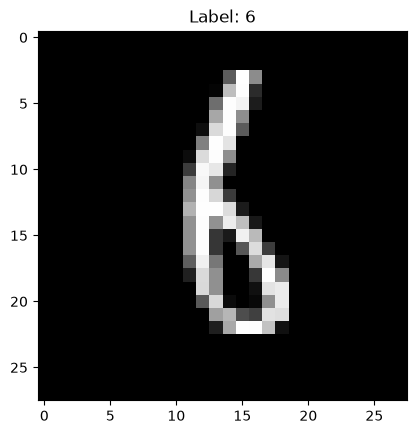

-----------------------------------------------------
Predicted digit: 6


In [18]:
# Actual Image
i = random.randrange(len(test_dataset))
image, label = test_dataset[i]

plt.imshow(image.squeeze(), cmap='gray')
plt.title(f"Label: {label}")
plt.show()
print('-----------------------------------------------------')

# Model Prediction
single_image = image.unsqueeze(0)
model.eval()

with torch.no_grad():
    output = model(single_image.to(device))

predicted_digit = torch.argmax(output, dim=1).item()

#print(f"Actual Value: {label}")
print(f"Predicted digit: {predicted_digit}")

## **Results**

### **Baseline Run**

#### **Architecture**
1 &rarr; 6 &rarr; 16 &rarr; 256 &rarr; 120 &rarr; 84 &rarr; 10
- Conv kernels: 5x5, stride 1
- Padding: 0
- Max pool: 2x2, stride 2
- Learning rate: 0.01
- Batch size: 64
- Epochs: 200

#### **Results**
- Best validation epoch: 51
- Validation loss: 0.0436
- Validation accuracy: 98.7%
- Test loss: 0.0378
- Test accuracy: 98.9%
- Training + validation time: 30m 50s
Best validation weights were restored before final testing.

### **Stride 2 Experiment**

#### **Architecture**
1 &rarr; 6 &rarr; 16 &rarr; 32 &rarr; 10

Changes from baseline:
- Conv kernels: 4x4, stride 2
- Fully connected classifier reduced because the representation became smaller

#### **Results**
- Best validation epoch: 161
- Validation loss: 0.1043
- Validation accuracy: 97.1%
- Training accuracy: 98.4%
- Test loss: 0.0904
- Test accuracy: 97.2%
- Training + validation time: 30m 35s
Best validation weights were restored before final testing.

**Observation**: The smaller kernel required for the stride increase reduced test accuracy by about 1.7% while saving only 15 seconds of training time. Because the architecture also had to be adjusted, this is a comparison between two model configurations rather than an isolated test of stride alone.

In [107]:
#torch.save(best_weights, "lenet5_baseline_best_weights.pth")